# 3. Model Development

**Project:** Credit Risk Scoring and Model Validation
**Objective:** Predict credit default by building Logistic Regression (champion model) and XGBoost (challenger model).

### Model Strategy
- **Champion Model:** Logistic Regression — preferred for interpretability and regulatory compliance
- **Challenger Model:** XGBoost — more complex structure, potential performance gain
- **Comparison Question:** Does the complex model really make a meaningful difference? Is it worth giving up explainability?

---

## 3.1 Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, classification_report,
                             confusion_matrix, precision_recall_curve, f1_score)
from sklearn.pipeline import Pipeline
import xgboost as xgb
import statsmodels.api as sm
import joblib
import os

plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('whitegrid')

print("Libraries loaded.")

Libraries loaded.


## 3.2 Loading and Preparing the Data

In [2]:
df = pd.read_csv('../data/credit_features.csv', index_col='ID')
print(f"Data: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Default rate: {df['DEFAULT_FLAG'].mean():.4f}")

Data: 30,000 rows, 42 columns
Default rate: 0.2212


In [3]:
# Select the features to use for modeling
# Use all numeric columns except the categorical band columns and the original target
exclude_cols = ['DEFAULT_FLAG', 'LIMIT_BAND', 'AGE_BAND']
feature_cols = [c for c in df.columns if c not in exclude_cols and df[c].dtype in ['int64', 'float64']]

X = df[feature_cols].copy()
y = df['DEFAULT_FLAG'].copy()

print(f"Number of features: {len(feature_cols)}")
print(f"\nFeatures used:")
for i, col in enumerate(feature_cols, 1):
    print(f"  {i:>2}. {col}")

Number of features: 39

Features used:
   1. LIMIT_BAL
   2. SEX
   3. EDUCATION
   4. MARRIAGE
   5. AGE
   6. PAY_0
   7. PAY_2
   8. PAY_3
   9. PAY_4
  10. PAY_5
  11. PAY_6
  12. BILL_AMT1
  13. BILL_AMT2
  14. BILL_AMT3
  15. BILL_AMT4
  16. BILL_AMT5
  17. BILL_AMT6
  18. PAY_AMT1
  19. PAY_AMT2
  20. PAY_AMT3
  21. PAY_AMT4
  22. PAY_AMT5
  23. PAY_AMT6
  24. MAX_DELINQUENCY
  25. AVG_DELINQUENCY
  26. DELINQUENCY_COUNT
  27. NEVER_DELINQUENT
  28. RECENT_DELINQUENT
  29. TOTAL_BILL
  30. TOTAL_PAY
  31. PAY_TO_BILL_RATIO
  32. RECENT_PAY_RATIO
  33. AVG_BILL
  34. AVG_PAY
  35. UTIL_RATIO
  36. AVG_UTIL_RATIO
  37. BILL_TREND
  38. PAY_TREND
  39. DELINQUENCY_TREND


## 3.3 Train / Test Split

We hold out 20% of the customers with a stratified random split, so both sets keep the same default rate.

**Note:** A production model would be tested out of time, on a later period. That is not possible here: the data has no date column, and every customer covers the same six months (April to September 2005), so the ID order is not a time order. Section 3.6 measures what happens if the last IDs are used as the test set anyway.

In [4]:
# Stratified random split: the data has no time axis
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Train set: {len(X_train):,} rows, default rate: {y_train.mean():.4f}")
print(f"Test set:  {len(X_test):,} rows, default rate: {y_test.mean():.4f}")
print(f"\nDefault rate difference: {abs(y_train.mean() - y_test.mean()):.4f}")

Train set: 24,000 rows, default rate: 0.2212
Test set:  6,000 rows, default rate: 0.2212

Default rate difference: 0.0000


In [5]:
# Scaling (required for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=feature_cols,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=feature_cols,
    index=X_test.index
)
print("StandardScaler applied.")

StandardScaler applied.


## 3.4 Champion Model: Logistic Regression

Logistic regression is the core tool of credit risk modeling in the banking sector. Its advantages:
- Interpretability (coefficients can be read directly as risk factors)
- Regulatory compliance (Basel III / BRSA requirements)
- Stability and reliability

In [6]:
# Detailed statistical output with statsmodels
# Columns that are linear combinations of other columns are left out here: with them the design matrix
# is singular and the standard errors and p-values mean nothing. The prediction models keep all features.
redundant = ['TOTAL_BILL', 'AVG_BILL', 'BILL_TREND', 'TOTAL_PAY', 'AVG_PAY', 'PAY_TREND',
             'DELINQUENCY_TREND', 'AVG_DELINQUENCY']
inference_cols = [c for c in feature_cols if c not in redundant]
X_train_sm = sm.add_constant(X_train_scaled[inference_cols])
print(f"Design matrix rank: {np.linalg.matrix_rank(X_train_sm.to_numpy())} of {X_train_sm.shape[1]} columns")

logit_model = sm.Logit(y_train, X_train_sm)
logit_result = logit_model.fit(disp=0, maxiter=100)

print(logit_result.summary2())

Design matrix rank: 32 of 32 columns
                          Results: Logit
Model:               Logit            Method:           MLE       
Dependent Variable:  DEFAULT_FLAG     Pseudo R-squared: 0.162     
Date:                2026-11-04 20:17 AIC:              21326.4088
No. Observations:    24000            BIC:              21585.1547
Df Model:            31               Log-Likelihood:   -10631.   
Df Residuals:        23968            LL-Null:          -12682.   
Converged:           1.0000           LLR p-value:      0.0000    
No. Iterations:      7.0000           Scale:            1.0000    
------------------------------------------------------------------
                   Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
------------------------------------------------------------------
const             -1.4954   0.0191 -78.2785 0.0000 -1.5328 -1.4579
LIMIT_BAL         -0.2351   0.0297  -7.9046 0.0000 -0.2934 -0.1768
SEX               -0.0652   0.0173  -3.7630 0.0002 

Statistically significant features (p<0.05): 13 / 31


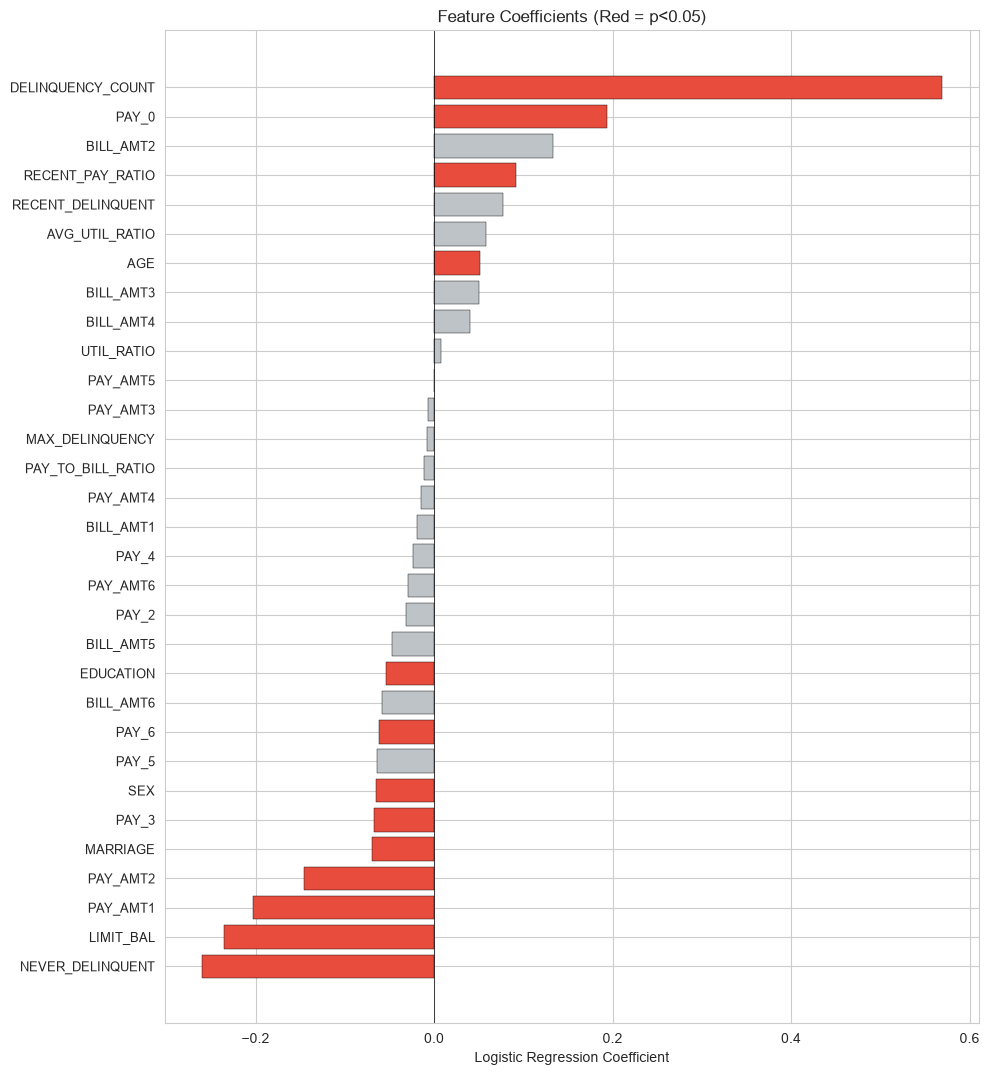

In [7]:
# Visualize the coefficients
coef_df = pd.DataFrame({
    'Feature': inference_cols,
    'Coefficient': logit_result.params[1:],  # excluding the constant
    'Std Error': logit_result.bse[1:],
    'z-value': logit_result.tvalues[1:],
    'p-value': logit_result.pvalues[1:]
}).sort_values('Coefficient', ascending=True)

# Significant features (p < 0.05)
sig_mask = coef_df['p-value'] < 0.05
print(f"Statistically significant features (p<0.05): {sig_mask.sum()} / {len(coef_df)}")

fig, ax = plt.subplots(figsize=(10, max(8, len(coef_df) * 0.35)))
colors = ['#e74c3c' if p < 0.05 else '#bdc3c7' for p in coef_df['p-value']]
ax.barh(range(len(coef_df)), coef_df['Coefficient'], color=colors, edgecolor='black', linewidth=0.3)
ax.set_yticks(range(len(coef_df)))
ax.set_yticklabels(coef_df['Feature'], fontsize=9)
ax.set_xlabel('Logistic Regression Coefficient')
ax.set_title('Feature Coefficients (Red = p<0.05)')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.savefig('../reports/03_logistic_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Scikit-learn Logistic Regression (for prediction)
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced',  # Imbalance adjustment
    C=1.0
)
lr_model.fit(X_train_scaled, y_train)

# Train and test predictions
y_train_prob_lr = lr_model.predict_proba(X_train_scaled)[:, 1]
y_test_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
y_test_pred_lr = lr_model.predict(X_test_scaled)

# Performance
train_auc_lr = roc_auc_score(y_train, y_train_prob_lr)
test_auc_lr = roc_auc_score(y_test, y_test_prob_lr)

print(f"=== Logistic Regression Performance ===")
print(f"Train AUC: {train_auc_lr:.4f}")
print(f"Test AUC:  {test_auc_lr:.4f}")
print(f"AUC Gap (overfit indicator): {train_auc_lr - test_auc_lr:.4f}")
print(f"\n{classification_report(y_test, y_test_pred_lr, target_names=['Non-Default', 'Default'])}")

=== Logistic Regression Performance ===
Train AUC: 0.7645
Test AUC:  0.7471
AUC Gap (overfit indicator): 0.0173

              precision    recall  f1-score   support

 Non-Default       0.87      0.79      0.83      4673
     Default       0.44      0.60      0.51      1327

    accuracy                           0.74      6000
   macro avg       0.66      0.69      0.67      6000
weighted avg       0.78      0.74      0.76      6000



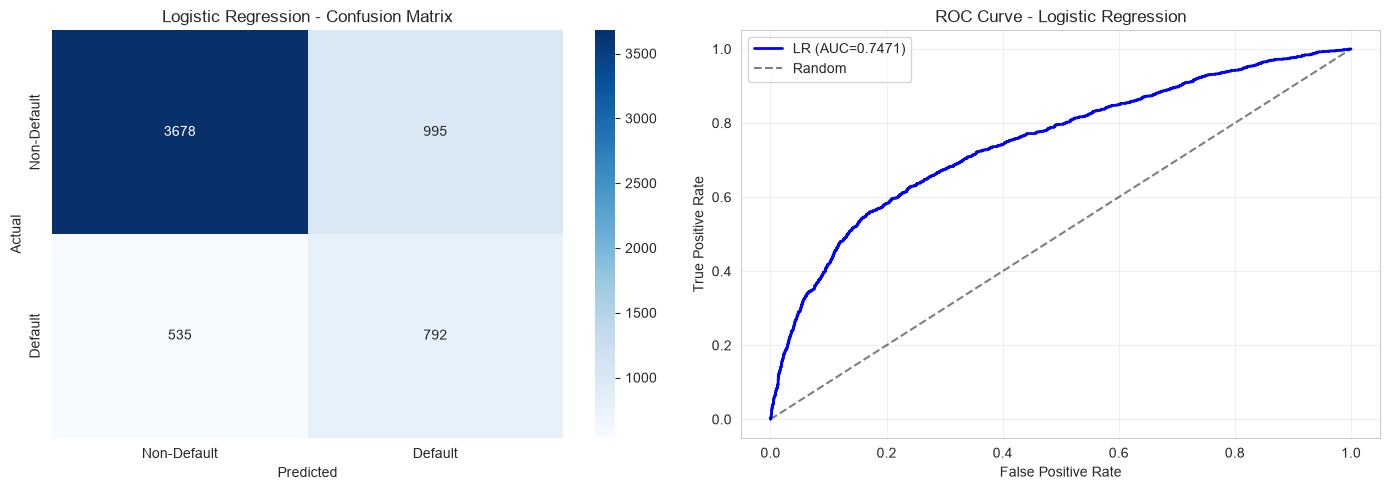

In [9]:
# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_test_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Non-Default', 'Default'],
            yticklabels=['Non-Default', 'Default'])
axes[0].set_title('Logistic Regression - Confusion Matrix')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_test_prob_lr)
axes[1].plot(fpr_lr, tpr_lr, 'b-', label=f'LR (AUC={test_auc_lr:.4f})', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve - Logistic Regression')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/03_lr_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.5 Challenger Model: XGBoost

XGBoost is a powerful ensemble method based on gradient boosting. Compared with the champion model:
- Higher accuracy potential
- Ability to capture non-linear relationships
- However, interpretability drops → a disadvantage from a validation perspective

In [10]:
# XGBoost model
# Early stopping watches a validation split taken from the training set; the test set stays untouched
X_fit, X_val, y_fit, y_val = train_test_split(X_train_scaled, y_train, test_size=0.2, stratify=y_train,
                                              random_state=42)

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum(),  # Imbalance adjustment
    random_state=42,
    eval_metric='auc',
    early_stopping_rounds=30,
    verbosity=0
)

xgb_model.fit(
    X_fit, y_fit,
    eval_set=[(X_val, y_val)],
    verbose=False
)

# Predictions
y_train_prob_xgb = xgb_model.predict_proba(X_train_scaled)[:, 1]
y_test_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]
y_test_pred_xgb = xgb_model.predict(X_test_scaled)

# Performance
train_auc_xgb = roc_auc_score(y_train, y_train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test, y_test_prob_xgb)

print(f"=== XGBoost Performance ===")
print(f"Train AUC: {train_auc_xgb:.4f}")
print(f"Test AUC:  {test_auc_xgb:.4f}")
print(f"AUC Gap (overfit indicator): {train_auc_xgb - test_auc_xgb:.4f}")
print(f"Best iteration: {xgb_model.best_iteration}")
print(f"\n{classification_report(y_test, y_test_pred_xgb, target_names=['Non-Default', 'Default'])}")

=== XGBoost Performance ===
Train AUC: 0.8193
Test AUC:  0.7830
AUC Gap (overfit indicator): 0.0363
Best iteration: 72

              precision    recall  f1-score   support

 Non-Default       0.88      0.80      0.84      4673
     Default       0.47      0.62      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.67      0.71      0.68      6000
weighted avg       0.79      0.76      0.77      6000



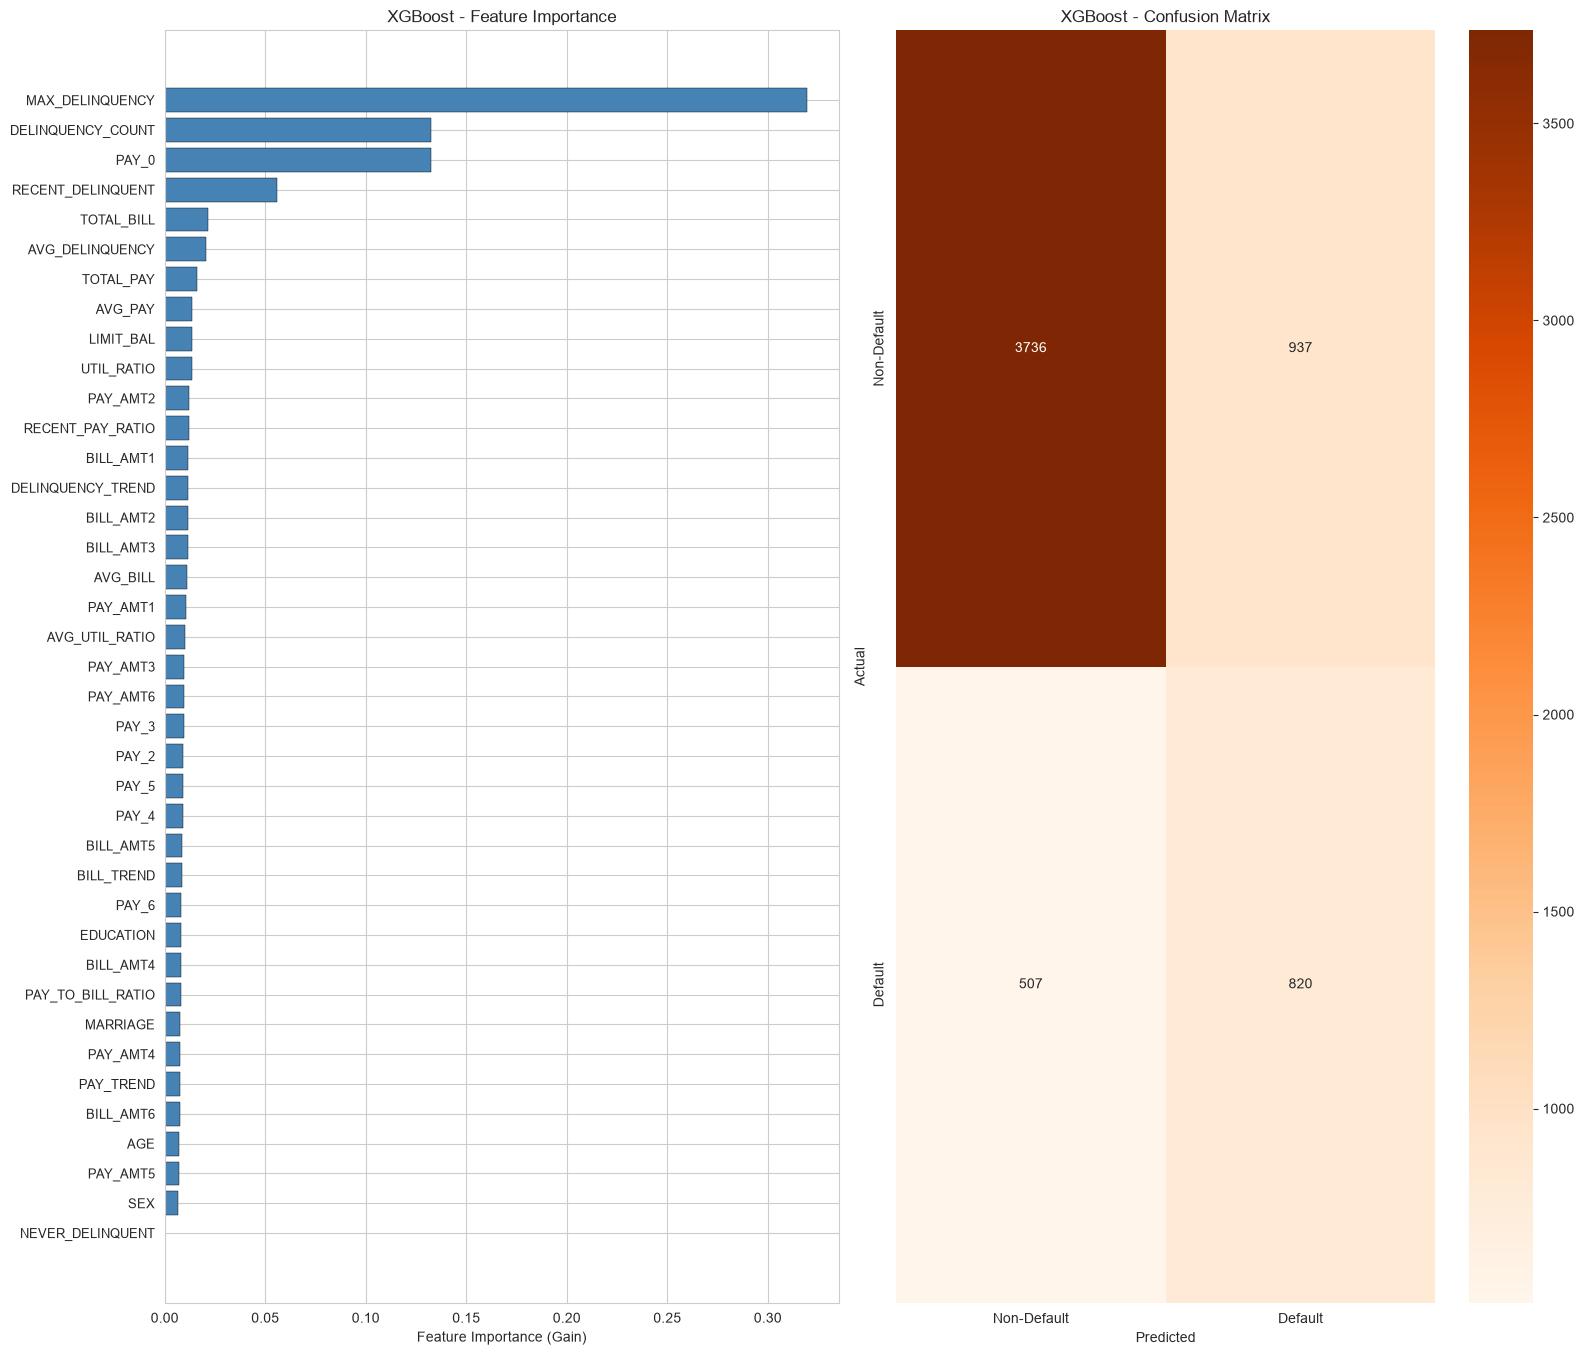

In [11]:
# XGBoost Feature Importance
importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, max(8, len(importance) * 0.35)))

# Feature importance
axes[0].barh(range(len(importance)), importance['Importance'],
             color='steelblue', edgecolor='black', linewidth=0.3)
axes[0].set_yticks(range(len(importance)))
axes[0].set_yticklabels(importance['Feature'], fontsize=9)
axes[0].set_xlabel('Feature Importance (Gain)')
axes[0].set_title('XGBoost - Feature Importance')

# Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_test_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Non-Default', 'Default'],
            yticklabels=['Non-Default', 'Default'])
axes[1].set_title('XGBoost - Confusion Matrix')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.savefig('../reports/03_xgb_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.6 Model Stability with Cross-Validation

In [12]:
# 5-Fold Stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# LR CV
lr_cv = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced', C=1.0)
lr_cv_scores = cross_val_score(lr_cv, X_train_scaled, y_train, cv=cv, scoring='roc_auc')

# XGBoost CV
xgb_cv = xgb.XGBClassifier(
    n_estimators=200, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=42, verbosity=0
)
xgb_cv_scores = cross_val_score(xgb_cv, X_train_scaled, y_train, cv=cv, scoring='roc_auc')

print("=== 5-Fold Cross-Validation Results (AUC) ===")
print(f"\nLogistic Regression:")
print(f"  Fold scores: {lr_cv_scores.round(4)}")
print(f"  Mean:        {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})")
print(f"\nXGBoost:")
print(f"  Fold scores: {xgb_cv_scores.round(4)}")
print(f"  Mean:        {xgb_cv_scores.mean():.4f} (+/- {xgb_cv_scores.std():.4f})")
print(f"\nDifference (XGB - LR): {(xgb_cv_scores.mean() - lr_cv_scores.mean()):.4f}")

=== 5-Fold Cross-Validation Results (AUC) ===

Logistic Regression:
  Fold scores: [0.7662 0.7661 0.7481 0.7564 0.7682]
  Mean:        0.7610 (+/- 0.0076)

XGBoost:
  Fold scores: [0.7861 0.7863 0.7719 0.7915 0.7878]
  Mean:        0.7847 (+/- 0.0067)

Difference (XGB - LR): 0.0237


### Why the test set is not the last 20% of IDs

An earlier version of this project used the last 20% of IDs as a "quasi out-of-time" test set. ID order is not time here, and the block turns out to be easier than average, so scores on it look better than the model deserves. The cell below repeats that split next to the cross-validated scores.

In [13]:
# The same models trained on the first 80% of IDs and scored on the last 20%
d = df.sort_index()
k = int(len(d) * 0.80)
s_id = StandardScaler().fit(d[feature_cols].iloc[:k])
A, B = s_id.transform(d[feature_cols].iloc[:k]), s_id.transform(d[feature_cols].iloc[k:])
ya, yb = d['DEFAULT_FLAG'].iloc[:k], d['DEFAULT_FLAG'].iloc[k:]
id_lr = roc_auc_score(yb, LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced', C=1.0)
                      .fit(A, ya).predict_proba(B)[:, 1])
id_xgb = roc_auc_score(yb, xgb.XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8,
                                             colsample_bytree=0.8, min_child_weight=3, random_state=42, verbosity=0,
                                             scale_pos_weight=(ya == 0).sum() / (ya == 1).sum())
                       .fit(A, ya).predict_proba(B)[:, 1])
print(f"{'':>22} {'5-fold CV':>10} {'last 20% of IDs':>16}")
print(f"{'Logistic Regression':>22} {lr_cv_scores.mean():>10.4f} {id_lr:>16.4f}")
print(f"{'XGBoost':>22} {xgb_cv_scores.mean():>10.4f} {id_xgb:>16.4f}")
print(f"\nDefault rate by block of 6,000 IDs: {[round(float(d['DEFAULT_FLAG'].iloc[i:i + 6000].mean()), 3) for i in range(0, len(d), 6000)]}")

                        5-fold CV  last 20% of IDs
   Logistic Regression     0.7610           0.7806
               XGBoost     0.7847           0.8041

Default rate by block of 6,000 IDs: [0.219, 0.23, 0.243, 0.203, 0.211]


## 3.7 Model Comparison Summary

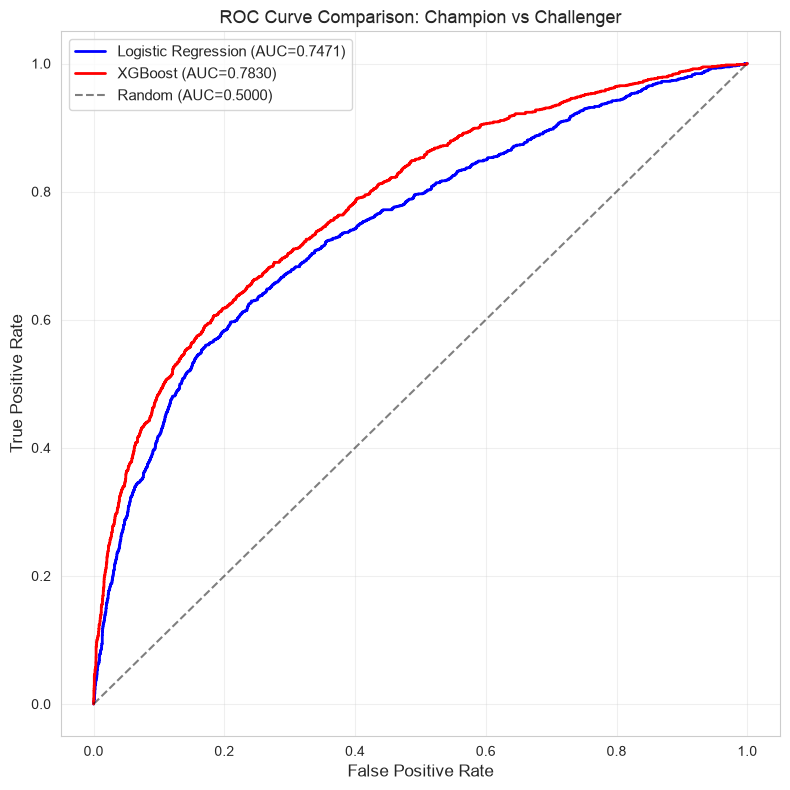

In [14]:
# ROC Curve comparison
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_test_prob_xgb)

fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(fpr_lr, tpr_lr, 'b-', label=f'Logistic Regression (AUC={test_auc_lr:.4f})', linewidth=2)
ax.plot(fpr_xgb, tpr_xgb, 'r-', label=f'XGBoost (AUC={test_auc_xgb:.4f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC=0.5000)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve Comparison: Champion vs Challenger', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/03_roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# Summary table
summary = pd.DataFrame({
    'Metric': ['Train AUC', 'Test AUC', 'Overfit (Train-Test)',
               'CV Mean AUC', 'CV Std', 'Test F1 (Default)'],
    'Logistic Regression': [
        f"{train_auc_lr:.4f}",
        f"{test_auc_lr:.4f}",
        f"{train_auc_lr - test_auc_lr:.4f}",
        f"{lr_cv_scores.mean():.4f}",
        f"{lr_cv_scores.std():.4f}",
        f"{f1_score(y_test, y_test_pred_lr):.4f}"
    ],
    'XGBoost': [
        f"{train_auc_xgb:.4f}",
        f"{test_auc_xgb:.4f}",
        f"{train_auc_xgb - test_auc_xgb:.4f}",
        f"{xgb_cv_scores.mean():.4f}",
        f"{xgb_cv_scores.std():.4f}",
        f"{f1_score(y_test, y_test_pred_xgb):.4f}"
    ]
})

print("=== Model Comparison Table ===")
print(summary.to_string(index=False))

=== Model Comparison Table ===
              Metric Logistic Regression XGBoost
           Train AUC              0.7645  0.8193
            Test AUC              0.7471  0.7830
Overfit (Train-Test)              0.0173  0.0363
         CV Mean AUC              0.7610  0.7847
              CV Std              0.0076  0.0067
   Test F1 (Default)              0.5087  0.5318


## 3.8 Saving the Models and Predictions

In [16]:
# Save the models
os.makedirs('../models', exist_ok=True)
joblib.dump(lr_model, '../models/logistic_regression.pkl')
joblib.dump(xgb_model, '../models/xgboost.pkl')
joblib.dump(scaler, '../models/scaler.pkl')

# Save the predictions (for the validation notebook)
predictions = pd.DataFrame({
    'y_true': y_test.values,
    'y_prob_lr': y_test_prob_lr,
    'y_prob_xgb': y_test_prob_xgb,
    'y_pred_lr': y_test_pred_lr,
    'y_pred_xgb': y_test_pred_xgb
}, index=y_test.index)
predictions.to_csv('../data/predictions.csv')

# Also save the train predictions (for the stability check)
train_predictions = pd.DataFrame({
    'y_true': y_train.values,
    'y_prob_lr': y_train_prob_lr,
    'y_prob_xgb': y_train_prob_xgb
}, index=y_train.index)
train_predictions.to_csv('../data/train_predictions.csv')

# Save the feature list
pd.Series(feature_cols).to_csv('../data/feature_list.csv', index=False, header=['feature'])

# Train/test metadata
meta = {
    'train_size': len(X_train),
    'test_size': len(X_test),
    'train_default_rate': y_train.mean(),
    'test_default_rate': y_test.mean(),
    'n_features': len(feature_cols),
    'lr_test_auc': test_auc_lr,
    'xgb_test_auc': test_auc_xgb,
    'lr_cv_auc': lr_cv_scores.mean(),
    'xgb_cv_auc': xgb_cv_scores.mean(),
    'lr_cv_std': lr_cv_scores.std(),
    'xgb_cv_std': xgb_cv_scores.std(),
    'split_method': 'stratified_random'
}
pd.Series(meta).to_csv('../data/model_metadata.csv', header=['value'])

print("Models and predictions saved.")
print(f"  models/logistic_regression.pkl")
print(f"  models/xgboost.pkl")
print(f"  models/scaler.pkl")
print(f"  data/predictions.csv")
print(f"  data/train_predictions.csv")

Models and predictions saved.
  models/logistic_regression.pkl
  models/xgboost.pkl
  models/scaler.pkl
  data/predictions.csv
  data/train_predictions.csv


## 3.9 Summary and Preliminary Assessment

### Model Performance
- Both models performed well above the baseline (random guess, AUC=0.50)
- Logistic Regression offers an interpretable and stable model
- XGBoost reaches a higher AUC but carries a higher overfit risk

### Questions to Answer in Validation
1. Is the model calibrated? (are the probability estimates reliable?)
2. In which segments does performance drop?
3. Is the challenger model really meaningfully better?
4. Do the score and feature distributions match between train and test?

### Next Step
A detailed model assessment will be carried out in the validation notebook (04).